# News Article Classification – Supervised ML Pipeline
**Dataset:** India Headlines News Dataset (Kaggle, `therohk`) – columns: `publish_date`, `headline_category`, `headline_text`.

**Pipeline:** raw text → preprocessing → TF-IDF features → model comparison → evaluation → export for Streamlit deployment.

> Run `text_utils.py` in the same folder as this notebook (it holds the shared cleaning function used by the app).

## 1. Setup & data loading

In [1]:
%%writefile text_utils.py
"""Shared text preprocessing. Used by the notebook AND the Streamlit app,
so training and inference apply exactly the same cleaning."""
import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

_STOP = set(ENGLISH_STOP_WORDS)
_URL = re.compile(r"http\S+|www\.\S+")
_NON_ALPHA = re.compile(r"[^a-z\s]")


def clean_text(text: str) -> str:
    """lowercase -> strip URLs -> keep letters only -> drop stopwords/1-char tokens."""
    text = str(text).lower()
    text = _URL.sub(" ", text)
    text = _NON_ALPHA.sub(" ", text)
    return " ".join(w for w in text.split() if w not in _STOP and len(w) > 1)


Writing text_utils.py


In [2]:
import json, re, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import sklearn, joblib
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import ComplementNB
from sklearn.svm import LinearSVC
from sklearn.linear_model import SGDClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from text_utils import clean_text

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
print("scikit-learn", sklearn.__version__)

scikit-learn 1.6.1


In [3]:
# --- Load data. Option A: kagglehub (Colab/Kaggle).  Option B: local CSV path. ---
import os
CSV_PATH = "india-news-headlines.csv"          # change if your file is elsewhere
if not os.path.exists(CSV_PATH):
    try:
        import kagglehub
        folder = kagglehub.dataset_download("therohk/india-headlines-news-dataset")
        CSV_PATH = os.path.join(folder, "india-news-headlines.csv")
    except Exception as e:
        raise FileNotFoundError("Download the CSV from Kaggle and set CSV_PATH.") from e

df = pd.read_csv(CSV_PATH)
print(df.shape)
df.head()

100%|██████████| 93.1M/93.1M [00:00<00:00, 203MB/s]

Extracting files...


(3876557, 3)


,publish_date,headline_category,headline_text
0,20010102,unknown,Status quo will not be disturbed at Ayodhya; s...
1,20010102,unknown,Fissures in Hurriyat over Pak visit
2,20010102,unknown,America's unwanted heading for India?
3,20010102,unknown,For bigwigs; it is destination Goa
4,20010102,unknown,Extra buses to clear tourist traffic


In [4]:
df.info()
print("\nMissing values:\n", df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3876557 entries, 0 to 3876556
Data columns (total 3 columns):
 #   Column             Dtype 
---  ------             ----- 
 0   publish_date       int64 
 1   headline_category  object
 2   headline_text      object
dtypes: int64(1), object(2)
memory usage: 88.7+ MB

Missing values:
 publish_date         0
headline_category    0
headline_text        0
dtype: int64
Duplicate rows: 25645


## 2. Label engineering
`headline_category` is hierarchical (e.g. `city.mumbai`, `sports.cricket`, `entertainment.hindi.bollywood`).
There are hundreds of leaf labels, so we use the **top-level category** (text before the first `.`) as the target,
drop the uninformative `unknown` bucket, and drop classes too small to learn or evaluate reliably.

In [5]:
df = df.dropna(subset=["headline_text", "headline_category"]).drop_duplicates(subset=["headline_text", "headline_category"])
df["label"] = df["headline_category"].str.split(".").str[0].str.strip().str.lower()
print("Distinct leaf categories :", df["headline_category"].nunique())
print("Distinct top-level labels:", df["label"].nunique())
df["label"].value_counts().head(25)

Distinct leaf categories : 1024
Distinct top-level labels: 336


,count
label,
city,2296818
india,305758
entertainment,233762
unknown,195081
business,160581
sports,128136
world,69161
home,54995
life-style,45863


In [6]:
DROP_LABELS = {"unknown"}
MIN_SAMPLES = 5000                       # keep classes with at least this many rows
counts = df["label"].value_counts()
keep = [l for l in counts.index if counts[l] >= MIN_SAMPLES and l not in DROP_LABELS]
df = df[df["label"].isin(keep)].reset_index(drop=True)
print("Kept classes:", keep)
print("Rows:", len(df))

Kept classes: ['city', 'india', 'entertainment', 'business', 'sports', 'world', 'home', 'life-style', 'tv', 'tech', 'citizen', 'news', 'edit-page', 'elections', 'delhi-times', 'top-headlines', 'bombay-times', 'blogs', 'lucknow-times', 'top-stories', 'calcutta-times', 'cricket', 'removed', 'pune-times', 'auto']
Rows: 3507123


## 3. Exploratory data analysis

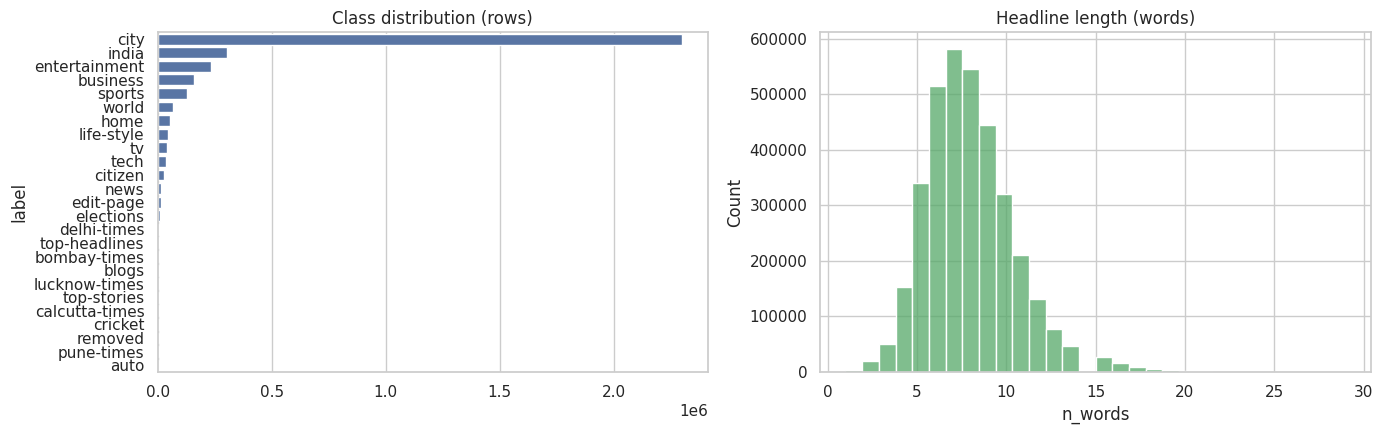

count    3.507123e+06
mean     7.949959e+00
std      2.642729e+00
min      1.000000e+00
25%      6.000000e+00
50%      8.000000e+00
75%      9.000000e+00
max      2.900000e+01
Name: n_words, dtype: float64


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
vc = df["label"].value_counts()
sns.barplot(x=vc.values, y=vc.index, ax=ax[0], color="#4C72B0"); ax[0].set_title("Class distribution (rows)")
df["n_words"] = df["headline_text"].str.split().str.len()
sns.histplot(df["n_words"], bins=30, ax=ax[1], color="#55A868"); ax[1].set_title("Headline length (words)")
plt.tight_layout(); plt.show()
print(df["n_words"].describe())

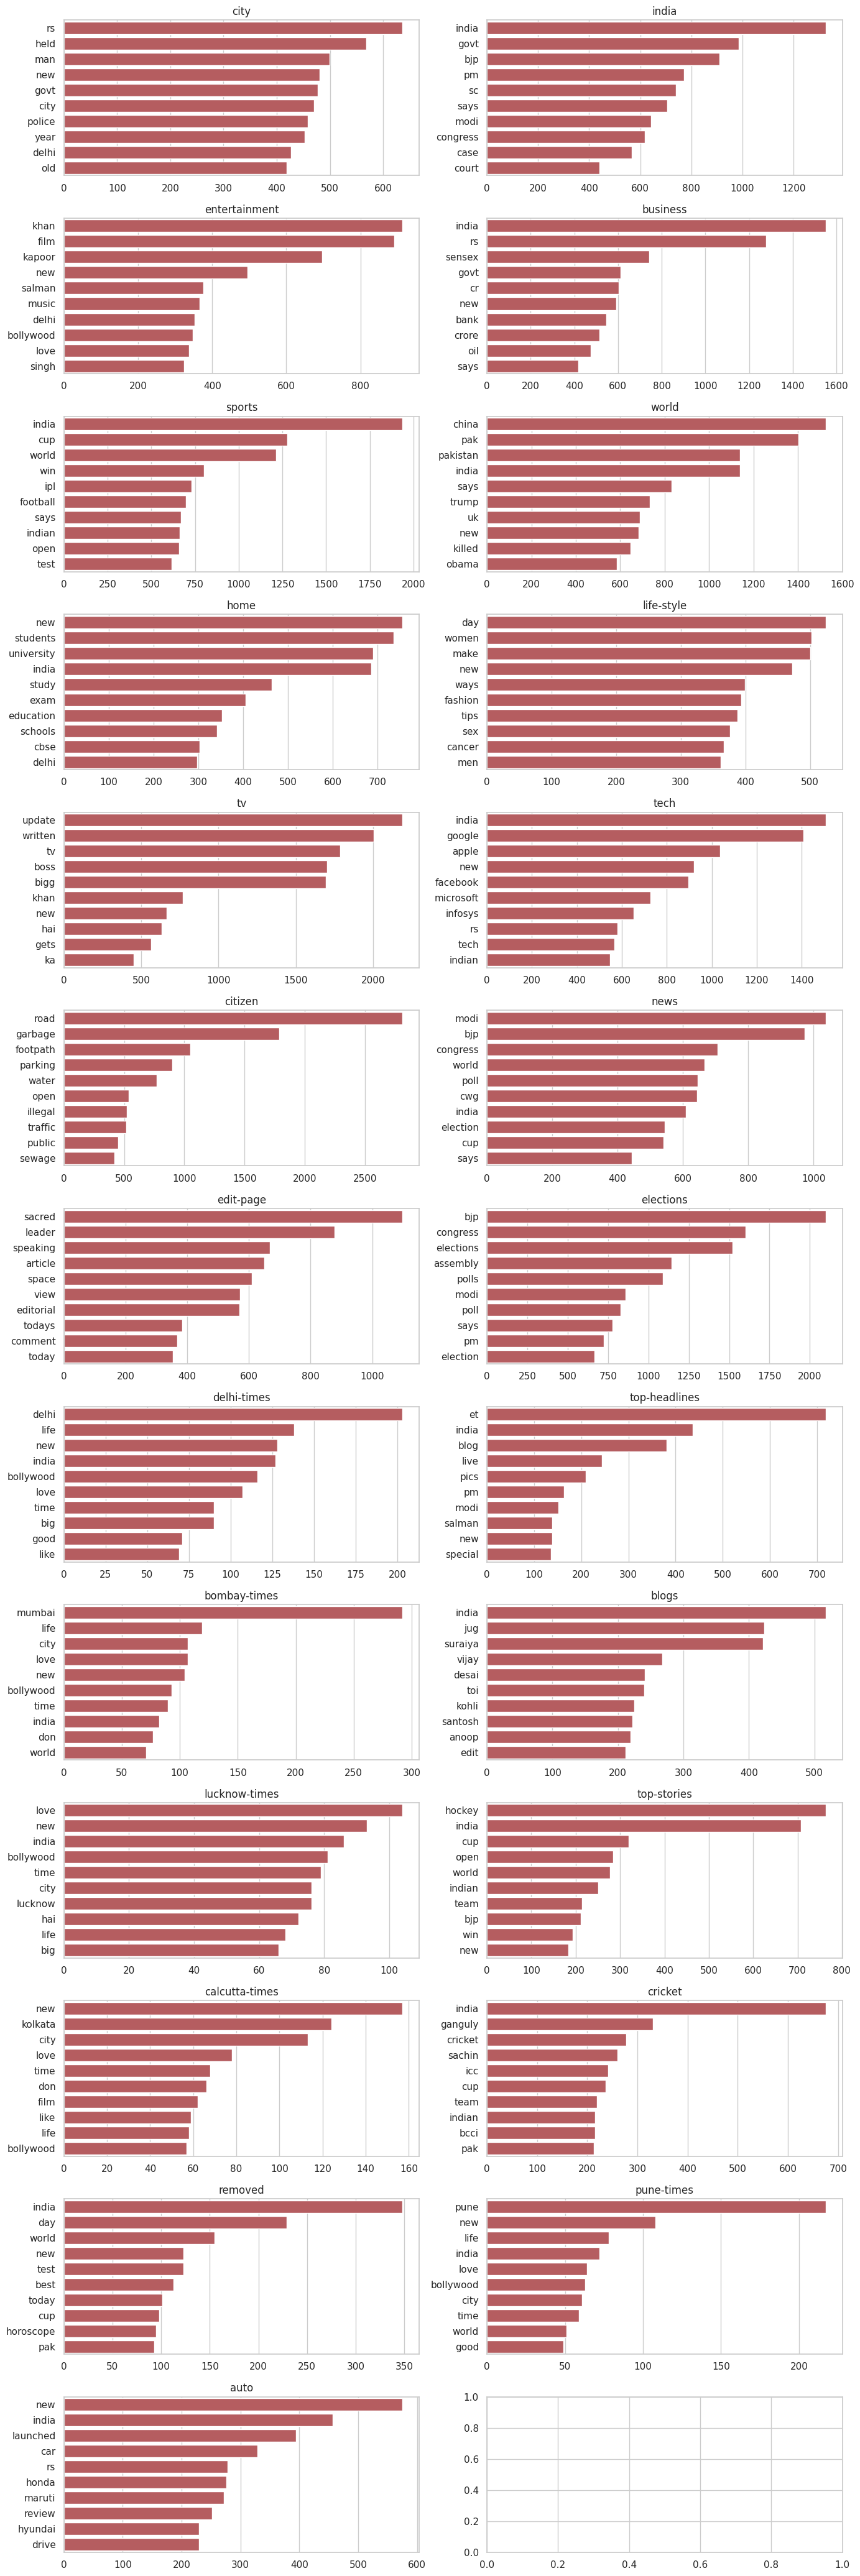

In [8]:
# Most frequent words per class (after cleaning, 20k-row sample per class for speed)
from collections import Counter
fig, axes = plt.subplots((len(keep)+1)//2, 2, figsize=(14, 3.2*((len(keep)+1)//2)))
for ax, lab in zip(axes.ravel(), keep):
    s = df[df.label == lab]["headline_text"].sample(min(20000, (df.label == lab).sum()), random_state=RANDOM_STATE)
    cnt = Counter(w for t in s.map(clean_text) for w in t.split()).most_common(10)
    sns.barplot(x=[c for _, c in cnt], y=[w for w, _ in cnt], ax=ax, color="#C44E52"); ax.set_title(lab)
plt.tight_layout(); plt.show()

## 4. Text preprocessing
Steps (in `text_utils.clean_text`): lowercase → remove URLs → remove digits/punctuation → remove English stop-words and 1-letter tokens.
Stemming/lemmatisation is deliberately skipped: headlines are short and named entities (`kohli`, `sensex`) are strong signals.

In [9]:
examples = df["headline_text"].sample(5, random_state=1)
for t in examples: print("RAW  :", t, "\nCLEAN:", clean_text(t), "\n")

RAW  : Allow operations from next week with 20 workers; says Gurgaon industry body 
CLEAN: allow operations week workers says gurgaon industry body 

RAW  : DP backlash effect: Hawking list to be revised 
CLEAN: dp backlash effect hawking list revised 

RAW  : Empowering Indian youth 
CLEAN: empowering indian youth 

RAW  : Panchkula parkings go under hammer 
CLEAN: panchkula parkings hammer 

RAW  : NTPC at 3rd place in market cap list 
CLEAN: ntpc rd place market cap list 



## 5. Train / test split
Stratified 80/20 split on the **natural** distribution (so test metrics reflect real-world class mix).
The training set is then capped per class to reduce majority-class dominance and speed up training; `class_weight='balanced'` handles the remaining skew.
Because classes are imbalanced, we report **macro-F1** alongside accuracy.

In [10]:
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df["label"], random_state=RANDOM_STATE)
CAP = 60000
train_df = pd.concat([g.sample(min(len(g), CAP), random_state=RANDOM_STATE)
                      for _, g in train_df.groupby("label")])
test_df = test_df.sample(min(len(test_df), 150000), random_state=RANDOM_STATE)
X_train, y_train = train_df["headline_text"], train_df["label"]
X_test,  y_test  = test_df["headline_text"],  test_df["label"]
print("train:", len(X_train), " test:", len(X_test))
print(y_train.value_counts())

train: 605655  test: 150000
label
business          60000
city              60000
sports            60000
india             60000
entertainment     60000
world             55329
home              43996
life-style        36690
tv                31806
tech              29370
citizen           23390
news              11125
edit-page         10754
elections          9101
delhi-times        5782
top-headlines      5591
bombay-times       5402
blogs              5328
lucknow-times      5293
top-stories        5270
calcutta-times     4526
cricket            4335
removed            4294
pune-times         4270
auto               4003
Name: count, dtype: int64


## 6. Feature representation – TF-IDF
Unigrams + bigrams, `min_df=3`, `max_features=100,000`, sublinear TF scaling. Cleaning is passed as the vectorizer's `preprocessor` so the saved pipeline accepts raw text.

In [11]:
tfidf = TfidfVectorizer(preprocessor=clean_text, ngram_range=(1, 2), min_df=3,
                        max_features=100_000, sublinear_tf=True)
t0 = time.time()
Xtr = tfidf.fit_transform(X_train)
Xte = tfidf.transform(X_test)
print("Feature matrix:", Xtr.shape, f"({time.time()-t0:.0f}s)")

Feature matrix: (605655, 100000) (20s)


## 7. Model building & comparison

In [12]:
models = {
    "Complement Naive Bayes": ComplementNB(alpha=0.3),
    "Linear SVM": LinearSVC(C=0.5, class_weight="balanced", random_state=RANDOM_STATE),
    "Logistic Regression (SGD)": SGDClassifier(loss="log_loss", alpha=1e-6, class_weight="balanced",
                                               max_iter=20, tol=None, random_state=RANDOM_STATE),
}
rows, fitted = [], {}
for name, m in models.items():
    t0 = time.time(); m.fit(Xtr, y_train); fitted[name] = m
    pred = m.predict(Xte)
    rows.append({"model": name,
                 "accuracy": accuracy_score(y_test, pred),
                 "macro_f1": f1_score(y_test, pred, average="macro"),
                 "weighted_f1": f1_score(y_test, pred, average="weighted"),
                 "train_sec": round(time.time()-t0, 1)})
results = pd.DataFrame(rows).sort_values("macro_f1", ascending=False).reset_index(drop=True)
results

,model,accuracy,macro_f1,weighted_f1,train_sec
0,Logistic Regression (SGD),0.553687,0.325449,0.616655,100.9
1,Linear SVM,0.541533,0.312716,0.605419,64.3
2,Complement Naive Bayes,0.558693,0.306834,0.596401,8.0


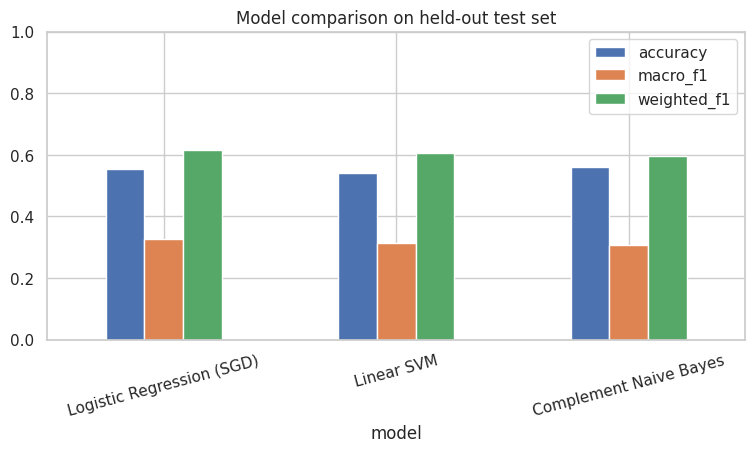

In [13]:
results.set_index("model")[["accuracy", "macro_f1", "weighted_f1"]].plot.bar(figsize=(9, 4), rot=15)
plt.ylim(0, 1); plt.title("Model comparison on held-out test set"); plt.show()

## 8. Hyper-parameter tuning (best linear model)
Small grid over regularisation strength, scored on macro-F1 using a held-out slice of the *training* data (the test set stays untouched).

In [14]:
best_name = results.loc[0, "model"]
print("Best baseline:", best_name)
Xa, Xv, ya, yv = train_test_split(Xtr, y_train, test_size=0.15, stratify=y_train, random_state=RANDOM_STATE)

def make(name, p):
    if name == "Linear SVM":                 return LinearSVC(C=p, class_weight="balanced", random_state=RANDOM_STATE)
    if name == "Complement Naive Bayes":     return ComplementNB(alpha=p)
    return SGDClassifier(loss="log_loss", alpha=p, class_weight="balanced", max_iter=20, tol=None, random_state=RANDOM_STATE)

grid = {"Linear SVM": [0.1, 0.3, 0.5, 1.0, 2.0],
        "Complement Naive Bayes": [0.05, 0.1, 0.3, 0.5, 1.0],
        "Logistic Regression (SGD)": [1e-7, 1e-6, 1e-5, 1e-4]}[best_name]
tune = []
for p in grid:
    m = make(best_name, p).fit(Xa, ya)
    tune.append((p, f1_score(yv, m.predict(Xv), average="macro")))
tune = pd.DataFrame(tune, columns=["param", "val_macro_f1"]); print(tune)
best_param = tune.sort_values("val_macro_f1").iloc[-1]["param"]
print("Chosen parameter:", best_param)

Best baseline: Logistic Regression (SGD)
          param  val_macro_f1
0  1.000000e-07      0.474191
1  1.000000e-06      0.486858
2  1.000000e-05      0.459011
3  1.000000e-04      0.395134
Chosen parameter: 1e-06


## 9. Final model & evaluation

In [15]:
final_clf = make(best_name, best_param).fit(Xtr, y_train)
# The app shows probabilities -> calibrate if the model has no predict_proba (e.g. LinearSVC)
if not hasattr(final_clf, "predict_proba"):
    final_clf = CalibratedClassifierCV(make(best_name, best_param), cv=3).fit(Xtr, y_train)

pipeline = Pipeline([("tfidf", tfidf), ("clf", final_clf)])
pred = pipeline.predict(X_test)
acc, mf1 = accuracy_score(y_test, pred), f1_score(y_test, pred, average="macro")
print(f"Test accuracy: {acc:.4f} | macro-F1: {mf1:.4f}\n")
print(classification_report(y_test, pred, digits=3))

Test accuracy: 0.5537 | macro-F1: 0.3254

                precision    recall  f1-score   support

          auto      0.187     0.763     0.301       190
         blogs      0.572     0.884     0.695       277
  bombay-times      0.018     0.167     0.033       288
      business      0.531     0.733     0.616      6800
calcutta-times      0.019     0.190     0.034       247
       citizen      0.216     0.828     0.343      1275
          city      0.958     0.515     0.670     98474
       cricket      0.146     0.566     0.233       226
   delhi-times      0.034     0.190     0.057       295
     edit-page      0.161     0.473     0.241       581
     elections      0.079     0.673     0.141       477
 entertainment      0.713     0.668     0.690      9947
          home      0.120     0.482     0.193      2374
         india      0.367     0.487     0.419     12882
    life-style      0.261     0.614     0.366      1921
 lucknow-times      0.027     0.169     0.046       296
     

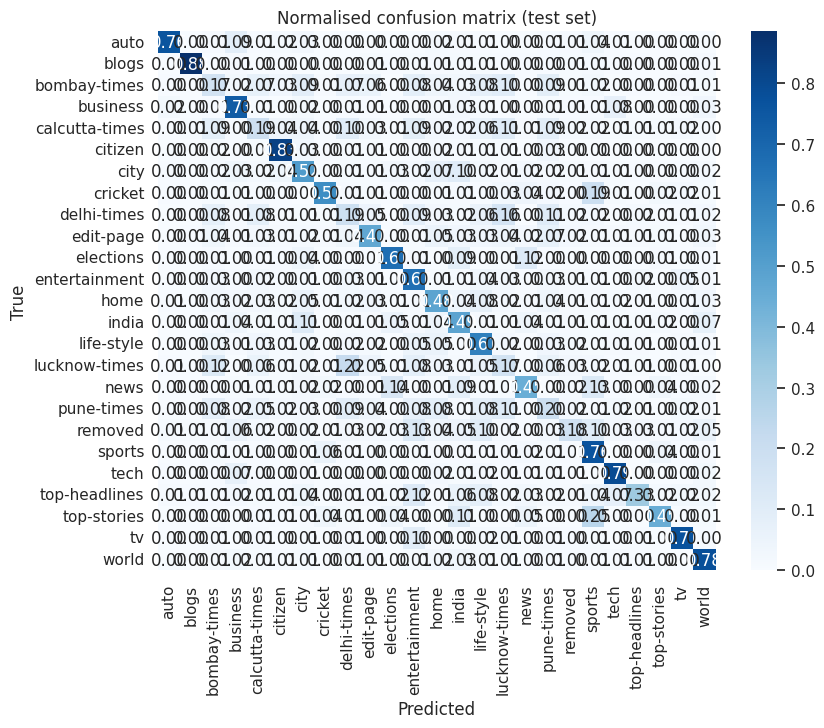

In [16]:
labels = sorted(y_test.unique())
cm = confusion_matrix(y_test, pred, labels=labels, normalize="true")
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Normalised confusion matrix (test set)"); plt.show()

## 10. Error analysis

In [17]:
err = test_df.assign(pred=pred)
err = err[err.label != err.pred]
print(f"Misclassified: {len(err):,} of {len(test_df):,} ({len(err)/len(test_df):.1%})")
print("\nMost common confusions (true -> predicted):")
print(err.groupby(["label", "pred"]).size().sort_values(ascending=False).head(10))
err[["headline_text", "label", "pred"]].sample(min(10, len(err)), random_state=3)

Misclassified: 66,947 of 150,000 (44.6%)

Most common confusions (true -> predicted):
label  pred          
city   india             10102
       home               7293
       citizen            3535
       business           3446
       elections          2896
       life-style         2283
       news               1927
       entertainment      1896
       calcutta-times     1727
       bombay-times       1668
dtype: int64


,headline_text,label,pred
8847,Rabindra Bharati V-C on hunger,city,calcutta-times
781986,Punjab cops warn of terror strikes during Games,city,india
109932,Why Kashmir became a US concern,home,india
3035632,Booze scam 'kingpin' gets bail because of 'men...,india,city
1235432,Baby survives fall from third floor,city,top-headlines
1551962,Minorities have been sidelined for govt scheme...,news,city
1331158,Despite CM's word; Maharashtra Public Service ...,city,home
2197171,Spurt in cyber fraud as online transactions go up,city,tech
2911306,NCB arrests six of cartel selling drugs in Delhi,city,india
1332454,Arunachal; Bangladesh discuss river management,city,removed


## 11. Sanity check with unseen text

In [18]:
tests = ["Kohli hits century as India beat Australia in second Test",
         "Sensex jumps 500 points as RBI keeps repo rate unchanged",
         "CBSE announces Class 12 results, pass percentage rises",
         "Shah Rukh Khan new film crosses Rs 100 crore at box office",
         "UN Security Council meets over Middle East conflict"]
for t in tests:
    p = pipeline.predict_proba([t])[0]
    print(f"{pipeline.classes_[p.argmax()]:<15} {p.max():.2f}  <- {t}")

sports          0.41  <- Kohli hits century as India beat Australia in second Test
business        0.91  <- Sensex jumps 500 points as RBI keeps repo rate unchanged
home            0.83  <- CBSE announces Class 12 results, pass percentage rises
entertainment   0.75  <- Shah Rukh Khan new film crosses Rs 100 crore at box office
world           0.61  <- UN Security Council meets over Middle East conflict


## 12. Export for deployment
Saves the full pipeline (raw text in, label out), metrics for the app sidebar, and a pinned `requirements.txt`
(pinning scikit-learn to the training version avoids pickle-version errors on Streamlit Cloud).

In [19]:
joblib.dump(pipeline, "news_classifier.joblib", compress=3)
json.dump({"best_model": best_name, "accuracy": float(acc), "macro_f1": float(mf1),
           "classes": [str(c) for c in pipeline.classes_]}, open("metrics.json", "w"), indent=2)
results.to_csv("model_comparison.csv", index=False)
import os; print("model size (MB):", round(os.path.getsize("news_classifier.joblib")/1e6, 1))

model size (MB): 20.4


In [20]:
# Write requirements.txt (does not require streamlit to be installed in this environment)
import scipy
reqs = f"""streamlit
scikit-learn=={sklearn.__version__}
pandas
numpy
scipy=={scipy.__version__}
joblib=={joblib.__version__}
"""
open("requirements.txt", "w").write(reqs); print(reqs)

streamlit
scikit-learn==1.6.1
pandas
numpy
scipy==1.16.3
joblib==1.6.0



In [21]:
# Round-trip test: reload exactly as the app does
m = joblib.load("news_classifier.joblib")
print(m.predict(["Sensex rallies as banking stocks surge"]))

['business']


## 13. Conclusions
* Top-level categories give a clean, learnable target from the hierarchical labels.
* TF-IDF (1–2 grams) + a linear classifier is a strong, fast, small-footprint baseline well suited to free-tier deployment.
* Most errors occur between **city / india / world** (overlapping geography) – a data limitation, not just a model one.
* Future work: transformer embeddings (DistilBERT), leaf-level categories, full-article training data.